# Vivienda en España: precios, territorio y contexto político

Primer bloque ejecutado con datos reales de INE y MIVAU, recuperados el **6 de octubre de 2026**.
Las figuras se reconstruyen con los snapshots versionados y se guardan en `reports/figures/block01/`.
El informe completo está en `reports/block_01_prices.md`.

**Pregunta:** ¿cuándo, cuánto y dónde han cambiado los precios, y qué gobiernos coincidieron con esos cambios?
Los gráficos describen coincidencias temporales; evaluar políticas necesita un diseño causal independiente.


## Histórico ampliado disponible

Empieza por [01b_price_history.ipynb](01b_price_history.ipynb) para ver compra desde
1995, alquiler desde 2011, municipios desde 2005, ciclos y gobiernos históricos.
Ese notebook contiene los cálculos y el código de gráficas visibles.
Este documento conserva la comparación reciente y los mapas iniciales.

In [1]:
from pathlib import Path
import json
import sys
import tempfile

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "data/snapshots/block01").exists(), "Ejecutar desde el repositorio o notebooks/"
sys.path.insert(0, str(ROOT / "src"))
from spain_housing.prices_analysis import run_analysis

previews = tempfile.TemporaryDirectory(prefix="housing-figures-")
preview_dir = Path(previews.name)
figures, findings = run_analysis(ROOT, preview_dir=preview_dir)
TABLES = ROOT / "reports/tables/block01"
SNAPSHOT = ROOT / "data/snapshots/block01"
print(f"{len(figures)} figuras generadas con datos reales; ventana común: {findings['common_window']}")

def show(*names):
    for name in names:
        display(Image(filename=str(preview_dir / f"{name}.png")))


16 figuras generadas con datos reales; ventana común: [2021, 2024]


## Fuentes y cobertura

Compra: IPV de transacciones, tasaciones €/m² y valor medio de transacciones de vivienda libre de segunda mano €/vivienda son conceptos distintos.
Alquiler: IPVA nacional (2021–2024) y medianas fiscales SERPAVI (2011–2024, según territorio), vivienda colectiva.
IPC: índice general anual, media de 12 meses. Se excluyen años parciales.
Navarra aporta medianas de alquiler desde 2021 y País Vasco desde 2024.
Los mapas son ilustrativos, con geometrías de 2014; los códigos se verifican antes de unirlos.


In [2]:
manifest = pd.DataFrame(json.loads((SNAPSHOT / "source_manifest.json").read_text()))
display(manifest[["source_file", "url", "sha256"]].head(9))


,source_file,url,sha256
0,valuations.csv,https://cdn.mivau.gob.es/portal-web-mivau/Dato...,21af4264fd80d617857885032a9a3164c19935dfb18afa...
1,rent.xlsx,https://cdn.mivau.gob.es/portal-web-mivau/vivi...,f00ca4d7f27d23f811b229d97e65e3854c4563f8a5f3f1...
2,ipv_quarterly.csv,https://www.ine.es/jaxiT3/files/t/csv_bdsc/795...,d41a9a8a99109d1f4b4a4686aca46556d91a8ec710d0b5...
3,ipva.csv,https://www.ine.es/jaxiT3/files/t/csv_bdsc/590...,fe20053978eb92fff2ac57e920d4ca2e0d073060130f4e...
4,cpi.csv,https://www.ine.es/jaxiT3/files/t/csv_bdsc/509...,b1b09db0ed5a9b0f2b177b8d6efc596f32bdd1f807b410...
5,municipal_purchase.xls,https://apps.fomento.gob.es/BoletinOnline2/sed...,e85101b09adf46a382b5a92a7f62f0ef636432c45fc8e4...
6,purchase_total.xls,https://apps.fomento.gob.es/BoletinOnline2/sed...,adb9c8db4fa0443d243c0799258c51a931d1eac70a63a5...
7,communities.geojson,https://raw.githubusercontent.com/codeforgerma...,2c17a7ef19ccf2974add6e3da782a4a1238a21272482cf...
8,provinces.geojson,https://raw.githubusercontent.com/codeforgerma...,562f0fe9329dcc575828454e994979732fe5dd5be5b470...


## 1. Evolución nacional

Niveles en sus unidades originales, tasas anuales y comparación base 100 en los mismos años.
La comparación de compra, alquiler general e IPC abarca **2011–2024**, con base **2011 = 100**.
No se obtiene una mediana nacional en euros promediando medianas regionales.


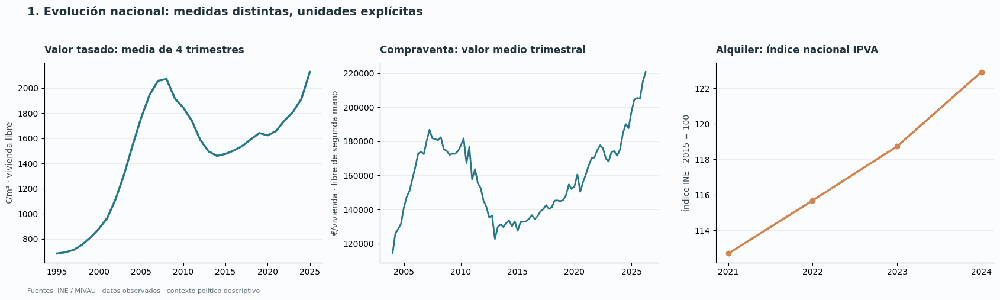

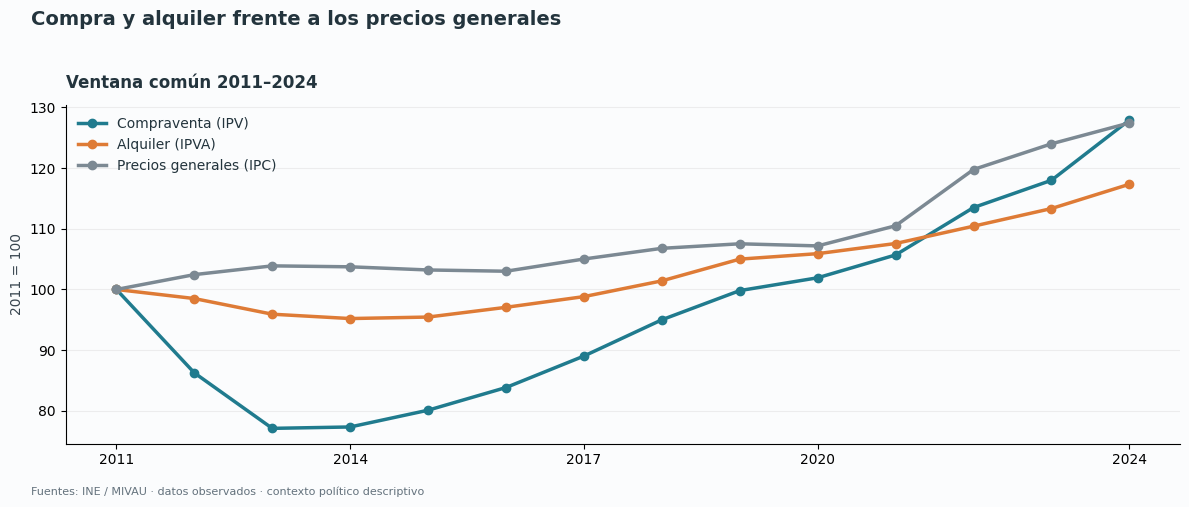

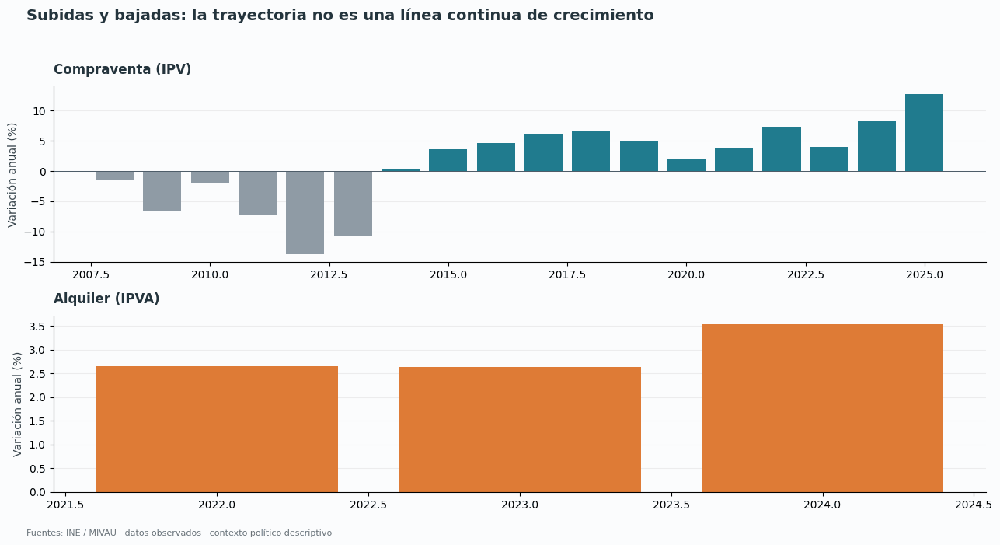

,year,purchase_nominal_index,rent_nominal_index,cpi_index,purchase_real_index,rent_real_index
0,2021,100.000000,100.000000,100.000000,100.000000,100.000000
1,2022,107.387950,102.653202,108.390576,99.074988,94.706760
2,2023,111.637445,105.353435,112.219323,99.481481,93.881724
3,2024,121.023151,109.074130,115.332487,104.934138,94.573639


In [3]:
show("01_national_levels", "03_indexed_comparison", "04_annual_changes")
display(pd.read_csv(TABLES / "national_comparison.csv"))


## 2. Gobiernos nacionales

Las franjas distinguen presidencias y coaliciones. Las medias anuales se dibujan a mitad de año.
La tabla selecciona años completos dentro de cada presidencia; la duración y el momento del ciclo difieren.
Ausencia de una serie de alquiler comparable significa «insuficiente», no un cambio igual a cero.


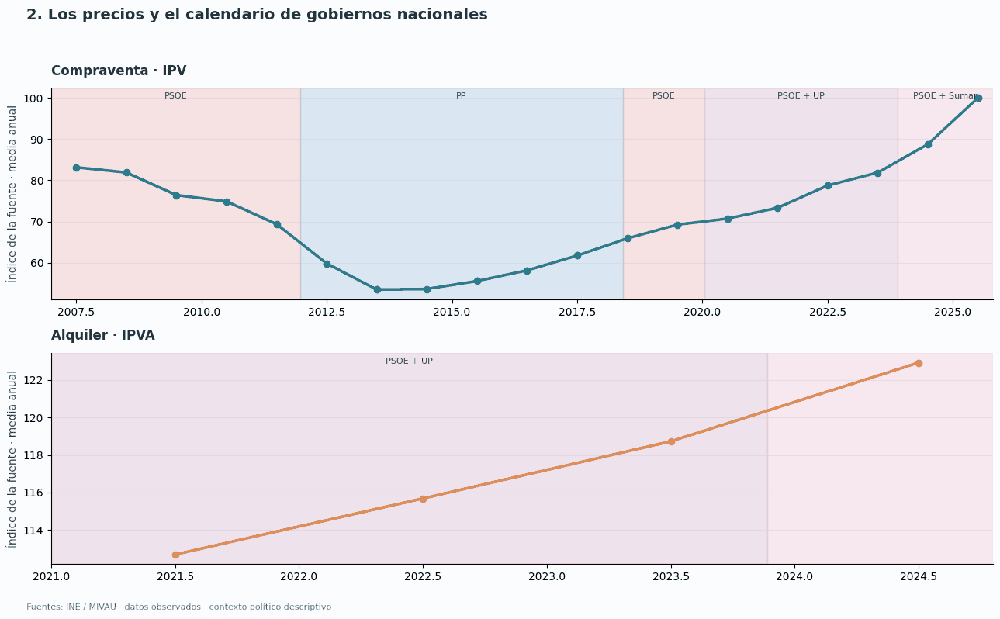

,president,political_context,purchase_window,purchase_change_pct,rent_window,rent_change_pct
0,Zapatero,PSOE,2007–2010,-9.929379,Insuficiente,NaN
1,Rajoy,PP,2012–2017,3.212036,Insuficiente,NaN
2,Sánchez,PSOE; coaliciones desde 2020,2019–2025,44.389737,2021–2024,9.07413


In [4]:
show("02_national_governments")
display(pd.read_csv(TABLES / "national_presidential_periods.csv"))


## 3. Inflación

Cambio acumulado: $(P_t/P_0-1)100$. Variación anual solo entre años consecutivos.
Cambio real: $[(P_t/P_0)/(IPC_t/IPC_0)-1]100$; no se resta simplemente la inflación.
Los índices reales se rebajan a una base común. El esfuerzo económico del hogar requiere ingresos.


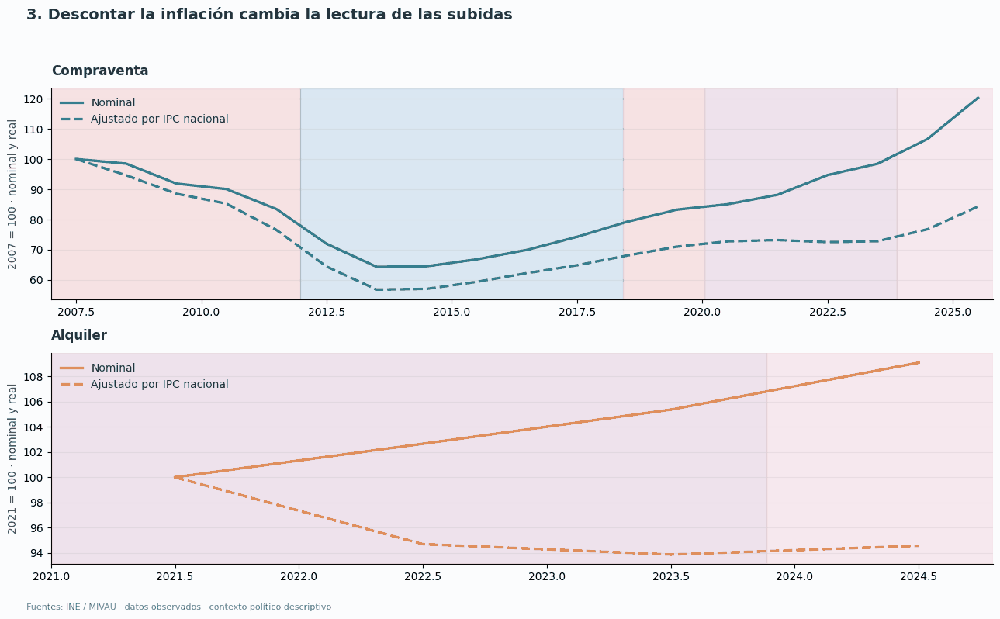

,Medida,Nominal (%),Real (%)
0,Compra,21.02,4.93
1,Alquiler,9.07,-5.43


In [5]:
show("05_inflation")
display(pd.DataFrame([
    {"Medida": "Compra", "Nominal (%)": findings["purchase_nominal_change_pct"],
     "Real (%)": findings["purchase_real_change_pct"]},
    {"Medida": "Alquiler", "Nominal (%)": findings["rent_nominal_change_pct"],
     "Real (%)": findings["rent_real_change_pct"]},
]).round(2))


## 4. Grandes ciudades, periferias, costa e interior

Muestra deliberada de 30 municipios. Series completas 2011–2024, rebasadas a 2011=100 y agregadas con igual peso por municipio.
La selección se publica; los grupos **no estiman** toda la costa, interior o periferias de España.
La clasificación urbana y la costera son dos dimensiones distintas.


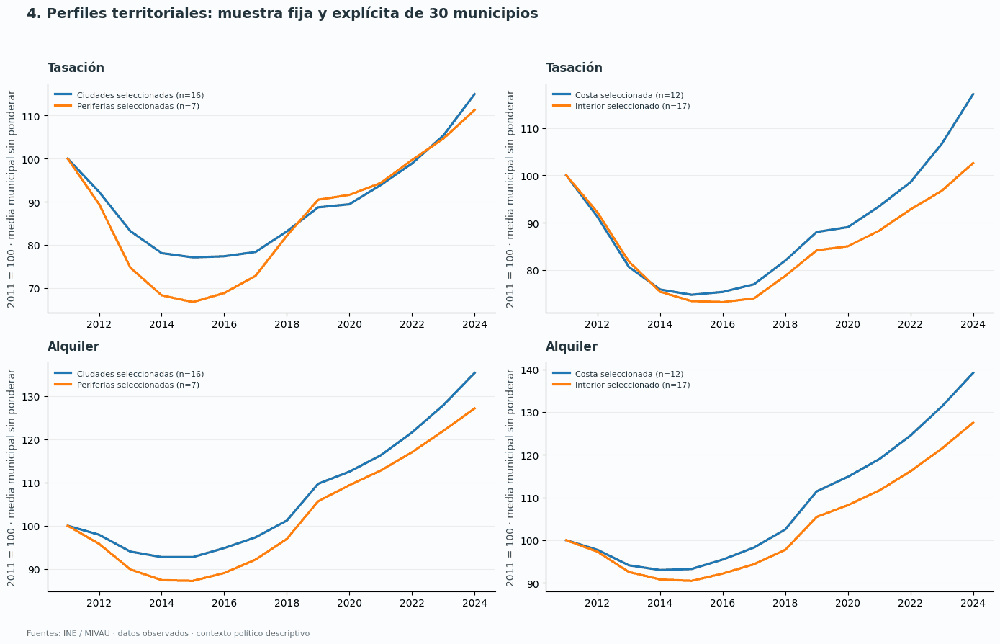

,market,group,municipalities,change_2011_2024_pct
0,Tasación,Ciudades seleccionadas,16,14.99
1,Tasación,Periferias seleccionadas,7,11.30
2,Tasación,Costa seleccionada,12,17.15
3,Tasación,Interior seleccionado,17,2.60
4,Alquiler,Ciudades seleccionadas,16,35.36
5,Alquiler,Periferias seleccionadas,7,27.12
6,Alquiler,Costa seleccionada,12,39.16
7,Alquiler,Interior seleccionado,17,27.52


,muniCode,muni,urban_category,coastal_category,lat,lng
0,08019,Barcelona,large_city,coastal,41.394535,2.159491
1,28079,Madrid,large_city,inland,40.426689,-3.665045
2,46250,València,large_city,coastal,39.464464,-0.365146
3,29067,Málaga,large_city,coastal,36.719665,-4.440700
4,50297,Zaragoza,large_city,inland,41.647377,-0.904087
5,41091,Sevilla,large_city,inland,37.383456,-5.967358
6,07040,Palma,large_city,coastal,39.556105,2.715493
7,03014,Alacant/Alicante,large_city,coastal,38.356682,-0.478835
8,47186,Valladolid,large_city,inland,41.641138,-4.726726
9,18087,Granada,large_city,inland,37.181705,-3.605910


In [6]:
show("06_territorial_profiles")
display(pd.read_csv(TABLES / "territorial_profiles.csv").round(2))
display(pd.read_csv(SNAPSHOT / "selected_cities.csv", dtype={"muniCode": str})[
    ["muniCode", "muni", "urban_category", "coastal_category", "lat", "lng"]])


## 5. Comunidades autónomas

Separar **nivel de precio de 2024** y **crecimiento 2011–2024**. El gris representa cobertura ausente, nunca precio cero.
Navarra y País Vasco aparecen en el mapa de alquiler de 2024; no disponen de extremos comparables para 2011–2024.


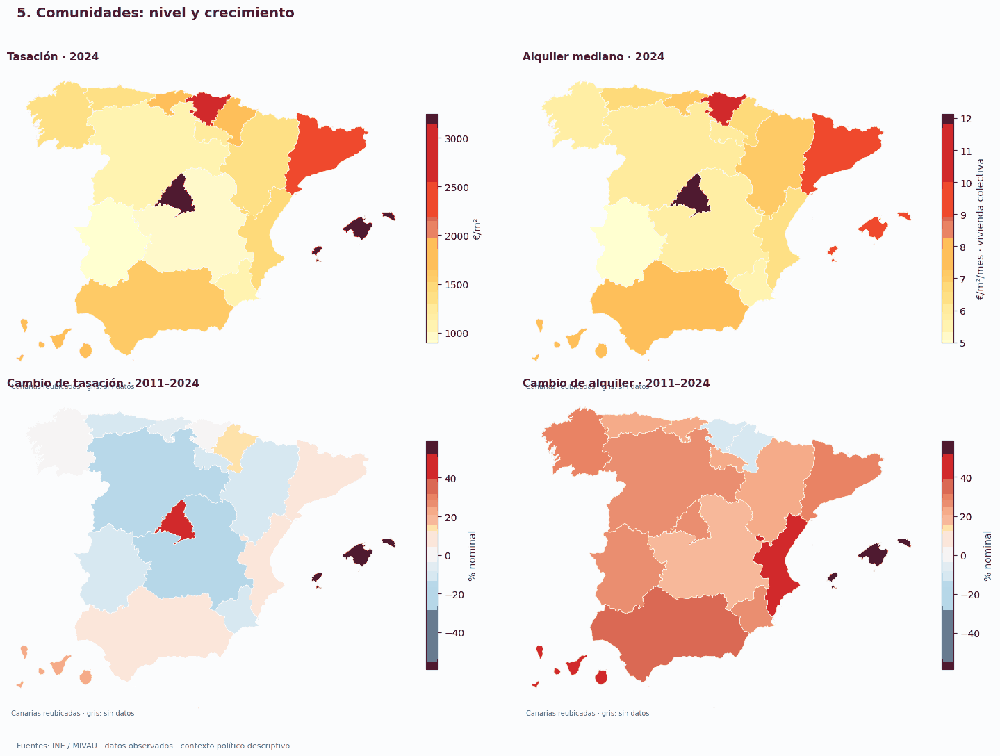

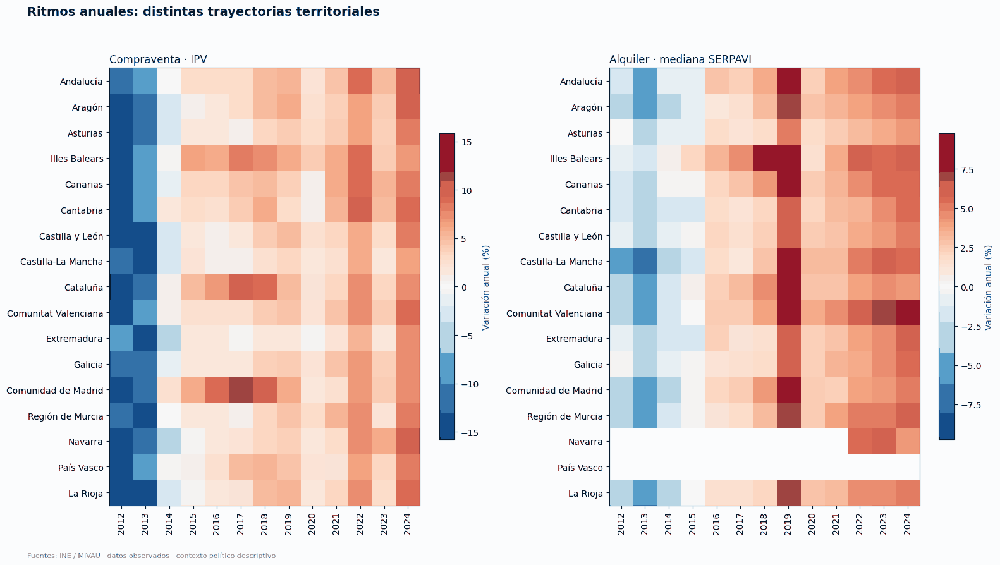

,code,name_purchase,first_year_purchase,last_year_purchase,first_value_purchase,last_value_purchase,change_pct_purchase,name_rent,first_year_rent,last_year_rent,first_value_rent,last_value_rent,change_pct_rent
0,01,Andalucía,2011,2024,1489.65,1597.08,7.21,Andalucía,2011,2024,5.47,7.35,34.50
1,02,Aragón,2011,2024,1541.40,1398.18,-9.29,Aragón,2011,2024,5.84,7.10,21.60
2,03,Asturias,2011,2024,1588.75,1418.02,-10.75,Principado de Asturias,2011,2024,5.42,6.62,22.19
3,04,Illes Balears,2011,2024,1990.85,3167.02,59.08,Illes Balears,2011,2024,6.06,9.62,58.56
4,05,Canarias,2011,2024,1489.45,1832.32,23.02,Canarias,2011,2024,5.56,7.75,39.47
5,06,Cantabria,2011,2024,1782.58,1654.68,-7.18,Cantabria,2011,2024,5.90,7.22,22.32
6,07,Castilla y León,2011,2024,1305.28,1092.82,-16.28,Castilla y León,2011,2024,4.69,5.97,27.36
7,08,Castilla-La Mancha,2011,2024,1173.30,975.38,-16.87,Castilla-La Mancha,2011,2024,4.86,5.86,20.45
8,09,Cataluña,2011,2024,2098.50,2306.43,9.91,Cataluña,2011,2024,7.51,9.84,31.00
9,10,Comunitat Valenciana,2011,2024,1357.22,1501.55,10.63,Comunitat Valenciana,2011,2024,4.44,6.32,42.24


In [7]:
show("07_regional_maps", "08_regional_heatmap")
display(pd.read_csv(TABLES / "regional_levels_and_growth.csv", dtype={"code": str}).round(2))


## 6. Presidencias autonómicas y precios

Franjas para las 17 comunidades, según dosieres del Senado. Se muestra el **partido de la presidencia**, no la coalición completa.
Años de transición excluidos de las comparaciones de intervalos. Se requieren al menos dos medias anuales comunes.
La base de los paneles es 2011=100 salvo las series forales de alquiler, donde se etiqueta el primer año observado.
Las tasas anualizadas permiten describir periodos de distinta duración, sin igualar sus contextos económicos.


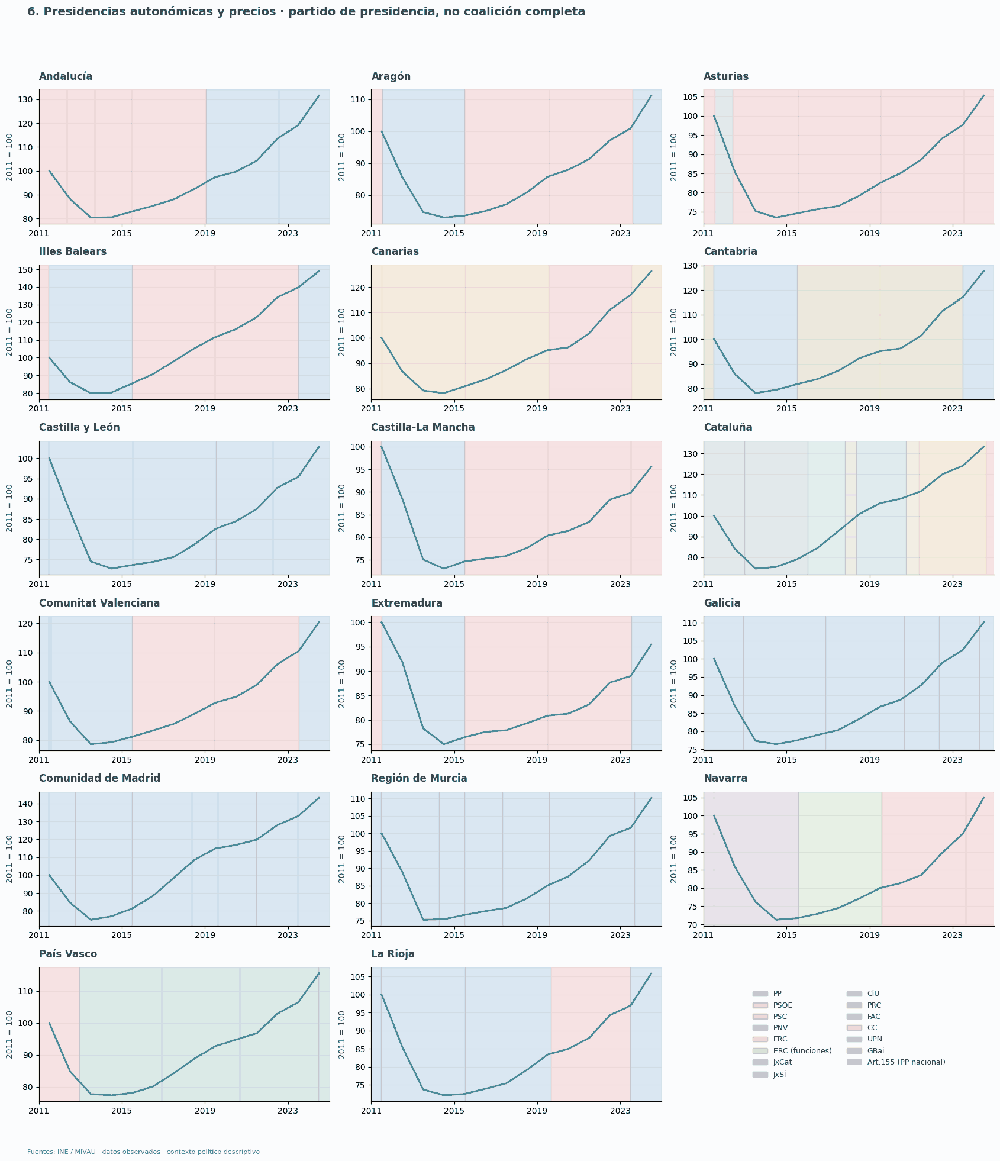

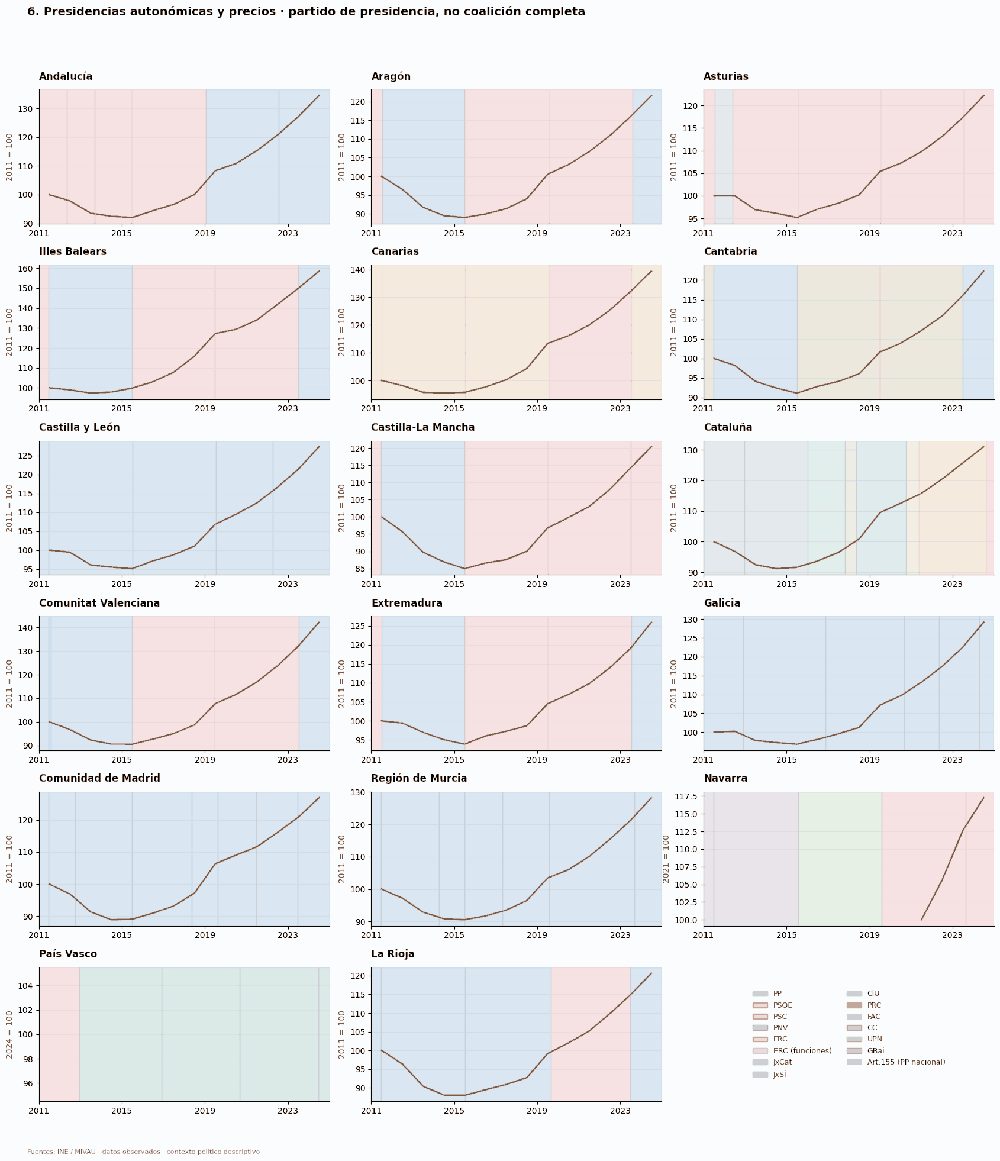

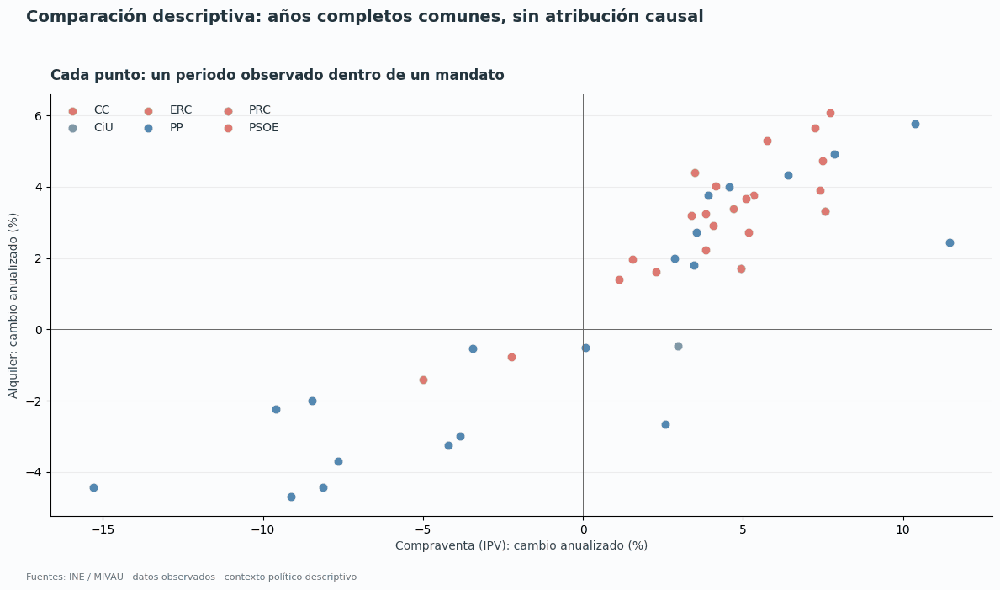

,name,party,first_year,last_year,purchase_annualised_pct,rent_annualised_pct
6,Cataluña,CiU,2013.0,2015.0,2.96,-0.46
10,Cataluña,ERC,2022.0,2023.0,3.50,4.40
13,Galicia,PP,2013.0,2015.0,0.08,-0.51
14,Galicia,PP,2017.0,2019.0,3.92,3.76
21,Andalucía,PSOE,2016.0,2018.0,4.06,2.91
22,Andalucía,PP,2020.0,2021.0,4.58,3.99
23,Andalucía,PP,2023.0,2024.0,10.38,5.78
26,Asturias,PSOE,2013.0,2014.0,-2.24,-0.77
27,Asturias,PSOE,2016.0,2018.0,2.29,1.62
28,Asturias,PSOE,2020.0,2022.0,5.17,2.72


In [8]:
show("09_regional_governments_purchase", "09_regional_governments_rent", "10_mandate_comparison")
mandates = pd.read_csv(TABLES / "regional_mandate_changes.csv", dtype={"code": str})
display(mandates.dropna(subset=["purchase_annualised_pct", "rent_annualised_pct"])[
    ["name", "party", "first_year", "last_year", "purchase_annualised_pct", "rent_annualised_pct"]].round(2))


## 7. Provincias y municipios

Mapas provinciales con cobertura verificable. Mapas municipales de los 30 casos seleccionados, geolocalizados con CartoCiudad e identificados por código INE.
Las tasaciones municipales son realmente municipales; no se asigna a una ciudad el valor de su provincia.
Alquiler por vivienda: mediana mensual de vivienda colectiva declarada, dependiente también de superficie y composición del parque.


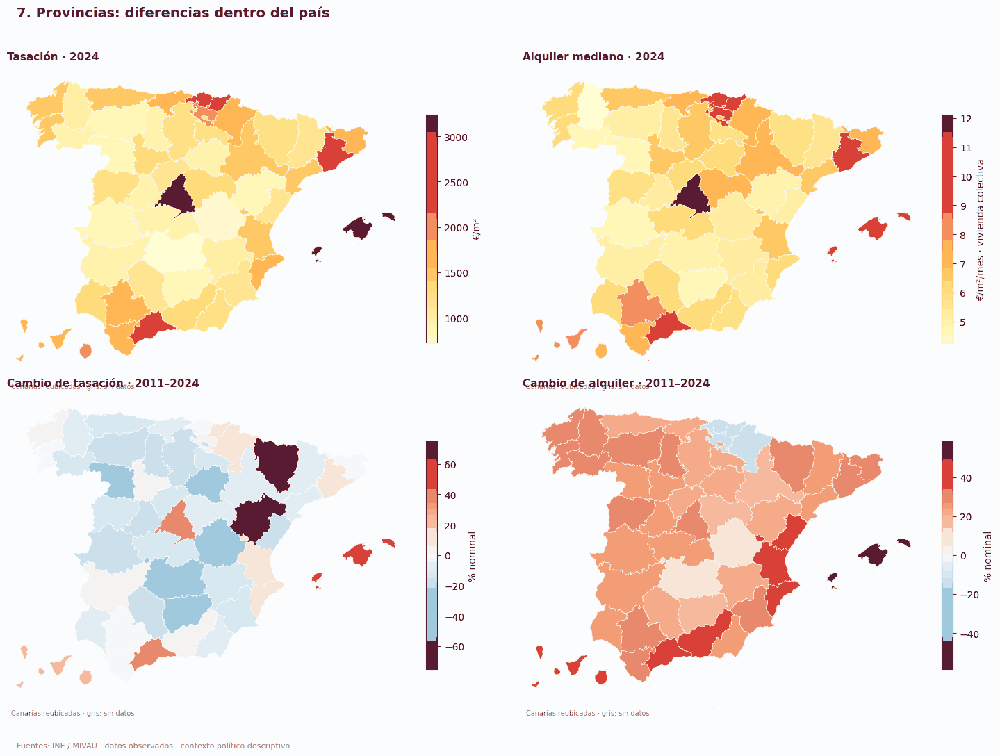

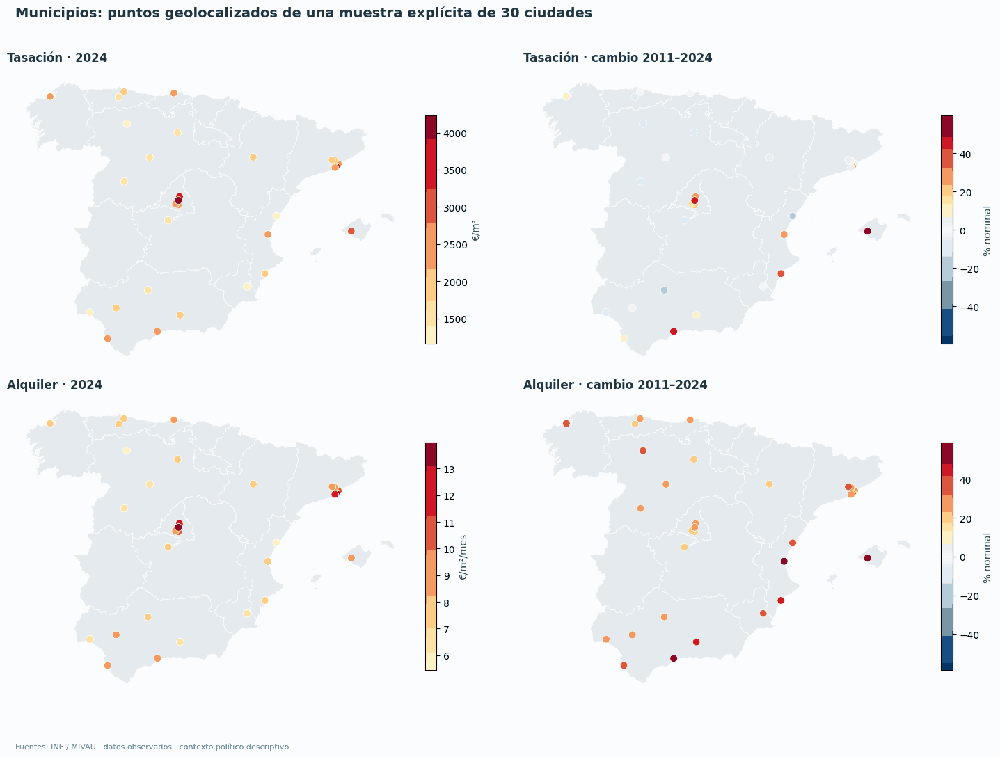

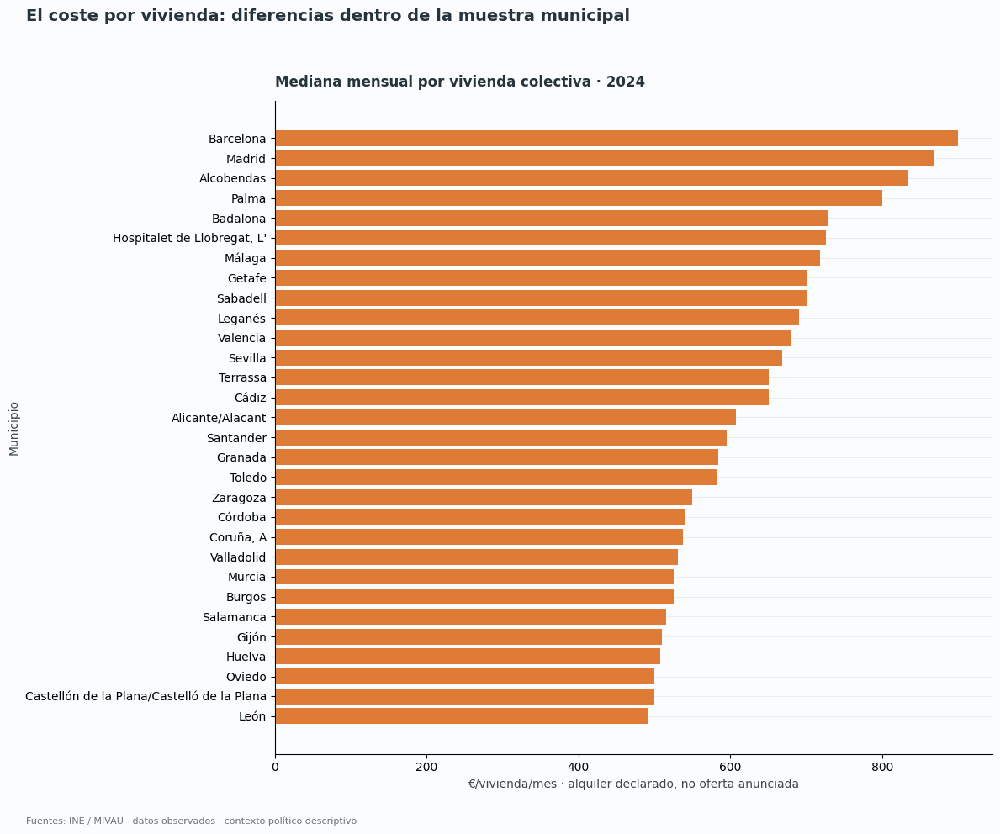

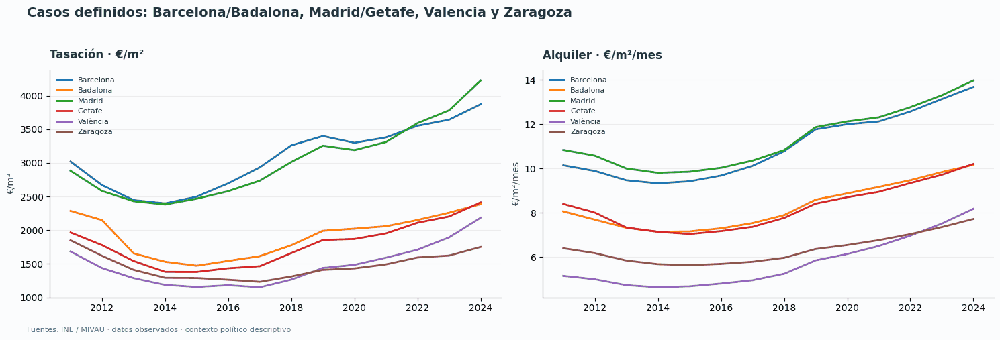

,code,name,first_year,last_year,first_value,last_value,change_pct,lat,lng,market
0,03014,Alacant/Alicante,2011,2024,1277.95,1757.15,37.50,38.36,-0.48,Tasación
1,07040,Palma,2011,2024,1861.22,2968.30,59.48,39.56,2.72,Tasación
2,08015,Badalona,2011,2024,2287.00,2387.57,4.40,41.46,2.24,Tasación
3,08019,Barcelona,2011,2024,3020.98,3872.62,28.19,41.39,2.16,Tasación
4,08101,L'Hospitalet de Llobregat,2011,2024,2379.98,2513.00,5.59,41.36,2.11,Tasación
5,08187,Sabadell,2011,2024,2110.80,2037.85,-3.46,41.56,2.10,Tasación
6,08279,Terrassa,2011,2024,1833.08,1907.60,4.07,41.58,2.01,Tasación
7,09059,Burgos,2011,2024,1805.60,1561.75,-13.51,42.35,-3.70,Tasación
8,11012,Cádiz,2011,2024,2359.10,2616.80,10.92,36.52,-6.28,Tasación
9,12040,Castelló de la Plana/Castellón de la Plana,2011,2024,1373.25,1162.82,-15.32,39.99,-0.05,Tasación


In [9]:
show("12_provincial_maps", "13_municipal_maps", "14_municipal_rent_totals", "15_municipal_cases")
display(pd.read_csv(TABLES / "selected_municipalities.csv", dtype={"code": str}).round(2))


## 8. Qué aportan los resultados al debate político

La tabla cuenta intervalos observados por adscripción de la presidencia: hay cambios de signo dentro de algunos partidos.
No se pondera por viviendas o población, y cada partido gobierna territorios y ciclos distintos. No es una evaluación de quién lo hace mejor.
Las hipótesis sobre oferta, turismo, fondos o leyes se contrastarán en sus bloques con variables específicas.
Para quien busca vivienda, la evolución de los contratos nuevos puede diferir de la del conjunto de alquileres.


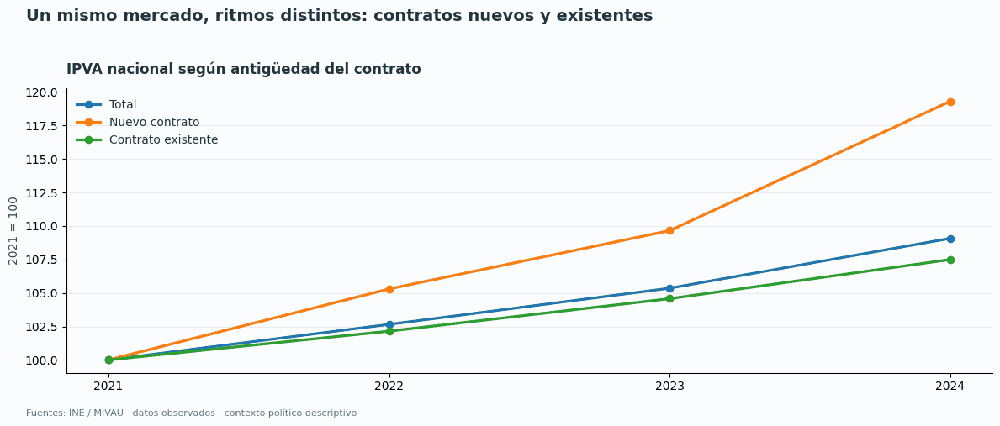

,party_of_presidency,observed_intervals,purchase_rising,purchase_falling,rent_rising,rent_falling
0,CC,2,1,1,1,1
1,CiU,1,1,0,0,1
2,ERC,1,1,0,1,0
3,PP,20,11,9,9,11
4,PRC,2,2,0,2,0
5,PSOE,17,16,1,16,1


**2021–2024:** contratos nuevos **+19.30%**; contratos existentes **+7.49%**.

Informe: reports/block_01_prices.md; tablas: reports/tables/block01/


In [10]:
show("16_rent_contracts")
display(pd.read_csv(TABLES / "party_observed_patterns.csv"))
display(Markdown(
    f"**2021–2024:** contratos nuevos **+{findings['new_contract_rent_change_pct']:.2f}%**; "
    f"contratos existentes **+{findings['existing_contract_rent_change_pct']:.2f}%**."
))
print("Informe: reports/block_01_prices.md; tablas: reports/tables/block01/")
previews.cleanup()
